In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
df = pd.read_csv("deces.csv", 
     usecols=
        [
        'nom',
        'prenoms',
        'sexe',
        'date_naissance',
        'date_deces',
        'code_insee_deces',
        'opposition'
        ],
)
df = df[df['opposition'] == False]

/tmp/ipykernel_9212/2162075475.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("deces.csv",


In [5]:
df.head(5)

,nom,prenoms,sexe,date_naissance,date_deces,code_insee_deces,opposition
0,RUMIANO,FERNANDO,M,19301001,20240113,01004,False
1,BONNET,YVONNE,F,19380514,20240103,01004,False
2,GEOFFRAY,RAYMONDE,F,19360408,20240124,01004,False
3,REISSER,"JEANNINE,HENRIETTE,EMILIE",F,19310315,20240112,01004,False
4,MAHIEU,"JEAN,RENE",M,19320430,20240124,01004,False


In [6]:
df['date_naissance'] = pd.to_datetime(df['date_naissance'], format='%Y%m%d', errors='coerce')
df['date_deces'] = pd.to_datetime(df['date_deces'], format='%Y%m%d', errors='coerce')
df['code_insee_deces'] = pd.to_numeric(df['code_insee_deces'], errors='coerce')
df.drop_duplicates(inplace=True)

In [7]:
all_deaths = df.groupby('date_deces').size().reset_index(name='count')
all_deaths = all_deaths[all_deaths['date_deces'].between('1975-01-01', '2023-12-31')]
all_deaths['year'] = pd.DatetimeIndex(all_deaths['date_deces']).year
all_deaths['month'] = pd.DatetimeIndex(all_deaths['date_deces']).month
all_deaths['day'] = pd.DatetimeIndex(all_deaths['date_deces']).day
all_deaths = all_deaths[~((all_deaths.month == 2) & (all_deaths.day == 29))]

all_deaths

,date_deces,count,year,month,day
4787,1975-01-01,1350,1975,1,1
4788,1975-01-02,1469,1975,1,2
4789,1975-01-03,1342,1975,1,3
4790,1975-01-04,1369,1975,1,4
4791,1975-01-05,1294,1975,1,5
...,...,...,...,...,...
22679,2023-12-27,2129,2023,12,27
22680,2023-12-28,2068,2023,12,28
22681,2023-12-29,2162,2023,12,29
22682,2023-12-30,2038,2023,12,30


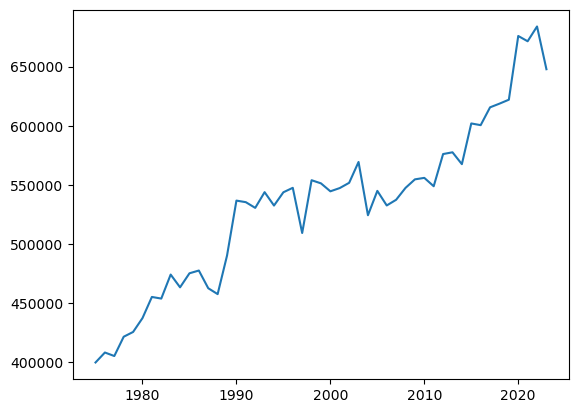

In [8]:
yearly = all_deaths['count'].groupby(all_deaths.year).sum()
plt.plot(yearly)

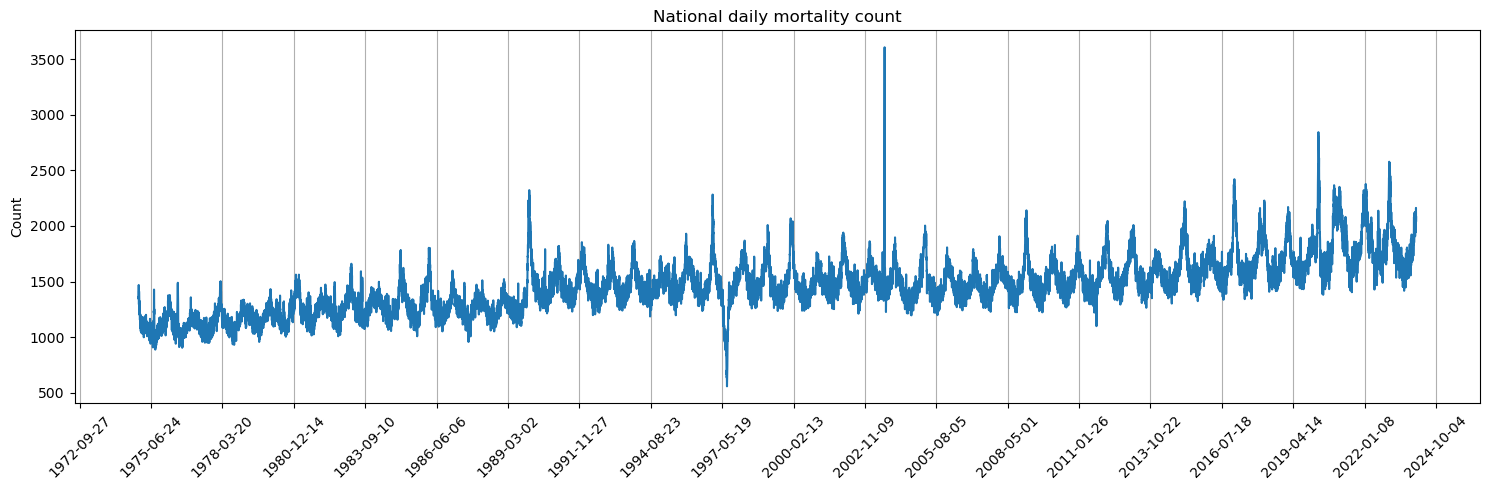

In [9]:
plt.figure(figsize=(15,5))
plt.plot(all_deaths['date_deces'], all_deaths['count'])
plt.grid(axis='x')
ax = plt.gca()
ax.xaxis.set_major_locator(plt.MaxNLocator(21))
plt.xticks(rotation=45)
plt.title("National daily mortality count")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("national_mort.png")
plt.show()


In [10]:
invalid_count_n = df['date_naissance'].isna().sum()
invalid_count_d = df['date_deces'].isna().sum()
invalid_count_c = df['code_insee_deces'].isna().sum()
print(f'Invalid naissance: {invalid_count_n/len(df)*100:.3f}%')
print(f'Invalid deces: {invalid_count_d/len(df)*100:.3f}%')
print(f'Invalid code: {invalid_count_c/len(df)*100:.3f}%')

df_pp = df.dropna(subset=['date_deces', 'code_insee_deces'])
df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')
print(f"Lost rows {(1-len(df_pp)/len(df))*100:.3f}%")
df_pp = df_pp[df_pp['date_deces'].between('1975-01-01', '2023-12-31')]
#df_pp = df_pp[df_pp['date_deces'].dt.month.isin([6, 7, 8, 9])]
df_pp['age'] = (df_pp['date_deces'] - df_pp['date_naissance']).dt.days // 365


Invalid naissance: 0.386%
Invalid deces: 0.003%
Invalid code: 0.333%


/tmp/ipykernel_9212/2979126279.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')


Lost rows 0.336%


Text(0.5, 1.0, 'National mortality')

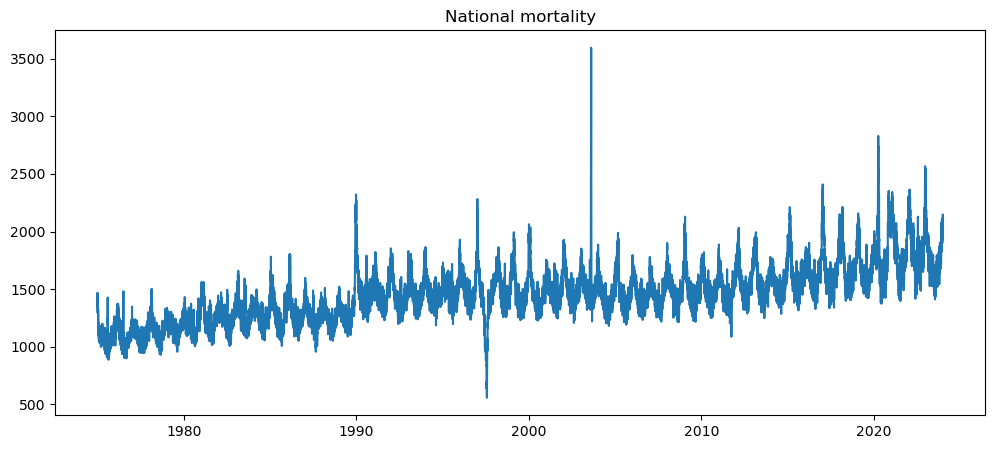

In [11]:
grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1975-01-01', end='2023-12-31', freq='D')
#date_range = date_range[date_range.month.isin([6, 7, 8, 9])]
 
# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)

plt.figure(figsize=(12,5))
plt.plot(final_df['date_deces'], final_df['count'])
plt.title("National mortality")

In [18]:
grouped_df['month'] = grouped_df['date_deces'].dt.to_period('M')
monthly_df = grouped_df.groupby('month')['count'].sum().reset_index()
monthly_df = monthly_df[monthly_df["month"].dt.year <= 2023]
#monthly_df['month'] = monthly_df['month'].astype(str)
monthly_df.head(13)

,month,count
0,1975-01,38496
1,1975-02,31125
2,1975-03,34261
3,1975-04,33522
4,1975-05,33026
5,1975-06,31450
6,1975-07,32179
7,1975-08,32878
8,1975-09,30746
9,1975-10,33989


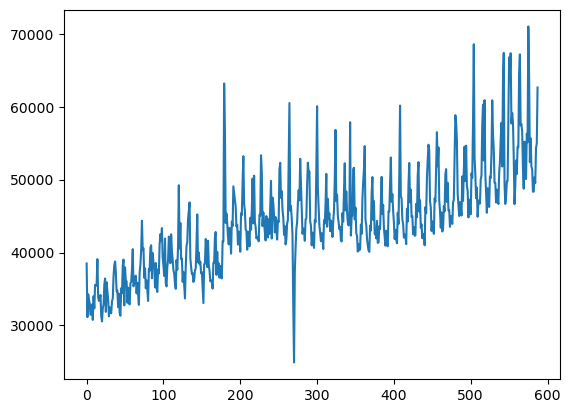

In [27]:
plt.plot(monthly_df['count'])


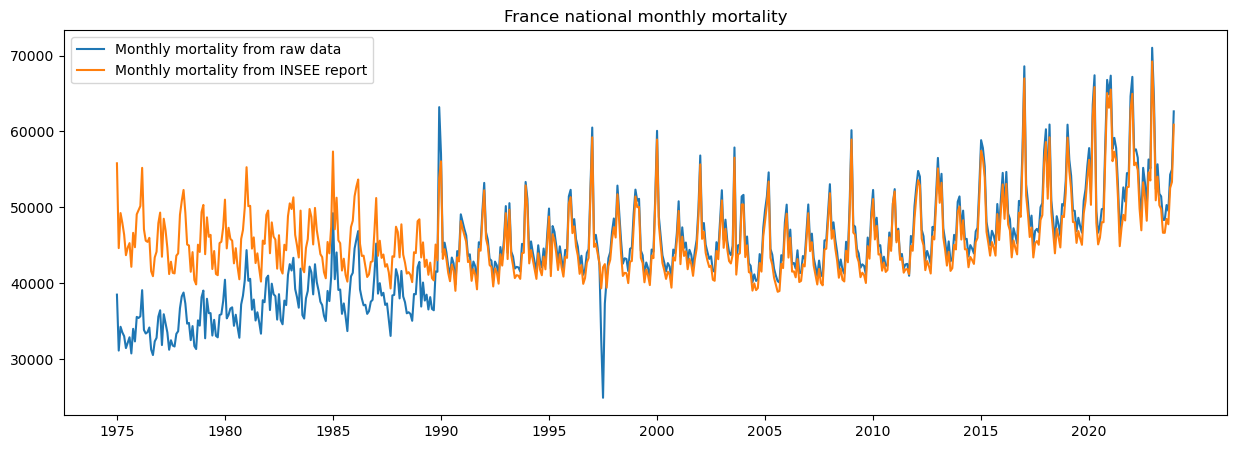

(588, 588)

In [44]:
monthly = pd.read_csv("valeurs_mensuelles.csv", sep=";", skiprows=3)
monthly['Période'] = pd.to_datetime(monthly['Période'], format='%Y-%m', errors='coerce')
monthly = monthly.sort_values(by='Période')
monthly = monthly[monthly["Période"].dt.year >= 1975]

x = 1975 + np.arange(0, 49*12) // 12
plt.figure(figsize=(15,5))
plt.plot(monthly_df['count'].values, label="Monthly mortality from raw data")
plt.plot(monthly["Unnamed: 1"].values, label="Monthly mortality from INSEE report")
ax = plt.gca()
ax.set_xticks(np.arange(0, len(monthly_df['count']), 12*5))
ax.set_xticklabels(x[::12*5])
plt.title("France national monthly mortality")
plt.legend()
plt.savefig("mortality_comparison.png")
plt.show()
len(monthly["Unnamed: 1"]), len(monthly_df['count'])

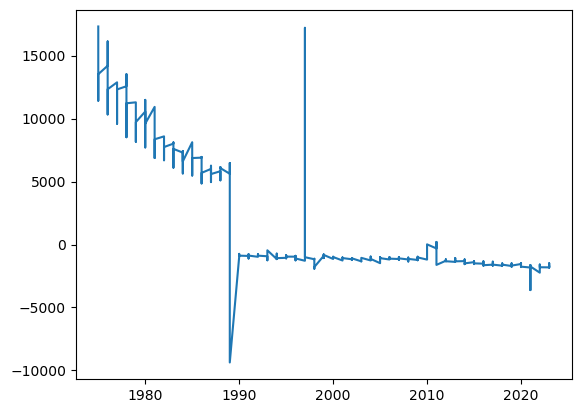

In [13]:
x = 1975 + np.arange(0, 49*12) // 12
plt.plot(x, monthly["Unnamed: 1"].values - monthly_df['count'].values)

In [14]:
grouped_df['date_deces'] = pd.to_datetime(grouped_df['date_deces'])
grouped_df['month'] = grouped_df['date_deces'].dt.to_period('M').dt.to_timestamp()
monthly['Période'] = pd.to_datetime(monthly['Période'])
monthly.rename(columns={'Période': 'month', 'Unnamed: 1': 'monthly_truth'}, inplace=True)

# Merge ground truth into daily dataframe
merged = pd.merge(grouped_df, monthly[['month', 'monthly_truth']], on='month', how='left')

# Calculate monthly sum of counts
monthly_sums = merged.groupby('month')['count'].transform('sum')

# Scale daily counts to match monthly ground truth
merged['adjusted_count'] = (merged['count'] / monthly_sums) * merged['monthly_truth']

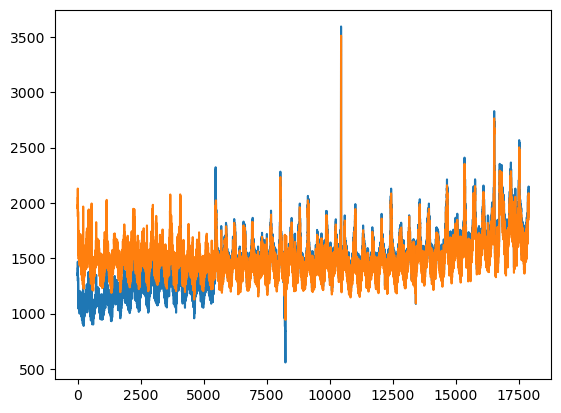

In [15]:
plt.plot(final_df['count'])
plt.plot(merged["adjusted_count"])

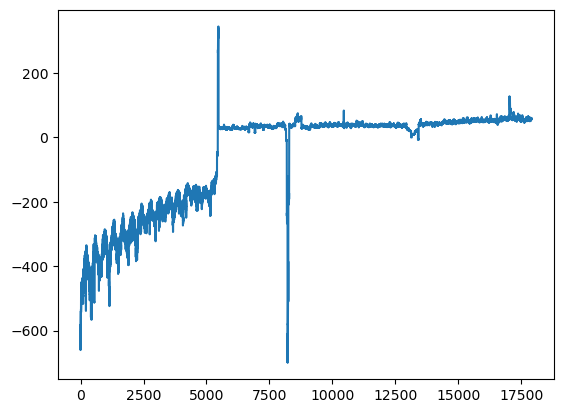

In [16]:
plt.plot(final_df['count'] - merged["adjusted_count"])

In [17]:
len(final_df['count']), len(monthly_sums), len(merged['monthly_truth'])

(17897, 17897, 17897)

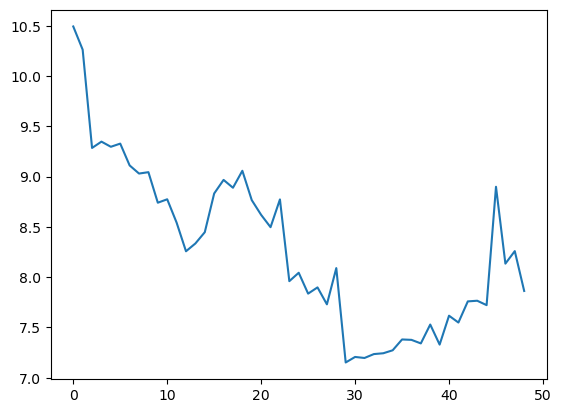

In [18]:
df_pp = df_pp[df_pp['code_insee_deces'] // 1000 == 75]
grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1975-01-01', end='2023-12-31', freq='D')
complete_df = pd.DataFrame({'date_deces': date_range})
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)

final_df['month'] = final_df['date_deces'].dt.to_period('M').dt.to_timestamp()
final_df['adjusted_count'] = (final_df['count'] / monthly_sums) * merged['monthly_truth']


yearly_paris_death = final_df.groupby(final_df['date_deces'].dt.year)['adjusted_count'].sum().values
annual_pop = pd.read_csv("annual_values.csv")


paris_yearly_rate = yearly_paris_death / annual_pop['Count']  * 1000
plt.plot(paris_yearly_rate)

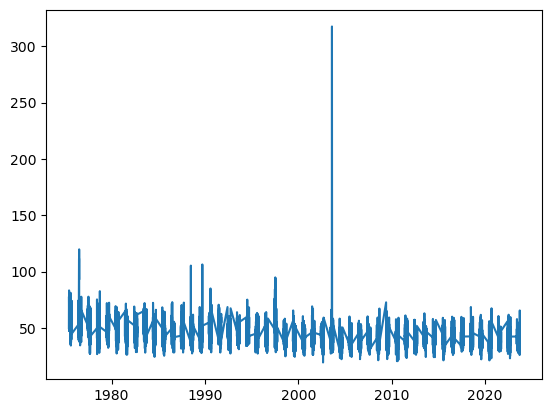

In [19]:
fmerged = merged[merged["date_deces"].dt.month.isin([6, 7, 8, 9])]
fmonthly_sums = fmerged.groupby('month')['count'].transform('sum')

grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1975-06-01', end='2023-09-30', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8, 9])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
final_df['adjusted_count'] = (final_df['count'].values / fmonthly_sums.values) * fmerged['monthly_truth'].values

plt.plot(final_df['date_deces'], final_df['adjusted_count'])
ts_mort_4 = np.array(final_df['adjusted_count'])
ts_rate_4 = ts_mort_4 / np.repeat(annual_pop['Count'].values, 122)

np.save("mortality_4.npy", ts_mort_4)
np.save("death_rate_jjas", ts_rate_4)

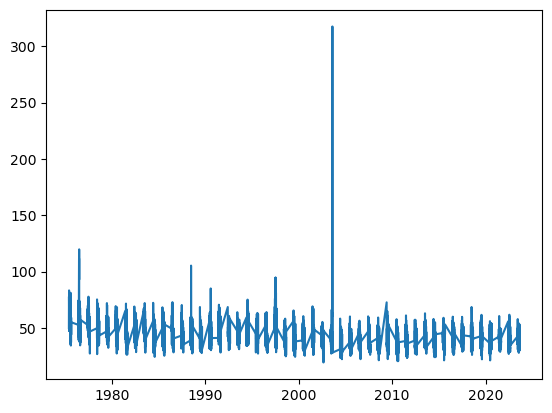

In [20]:
grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1975-01-01', end='2023-12-31', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8])]  # Keep only summer months

fmerged = merged[merged["date_deces"].dt.month.isin([6, 7, 8])]
fmonthly_sums = fmerged.groupby('month')['count'].transform('sum')


# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
final_df['adjusted_count'] = (final_df['count'].values / fmonthly_sums.values) * fmerged['monthly_truth'].values

plt.plot(final_df['date_deces'], final_df['adjusted_count'])
ts_mort = np.array(final_df['adjusted_count'])
ts_rate = ts_mort / np.repeat(annual_pop['Count'].values, 92)
np.save("mortality.npy", ts_mort)
np.save("death_rate_jja", ts_rate)

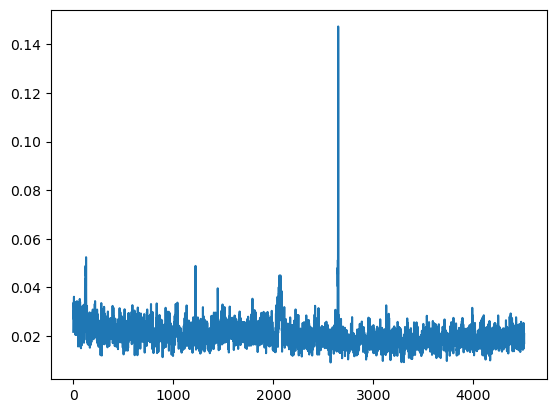

In [21]:
plt.plot(ts_rate*1000)